# [GSE133600](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE133600)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2021-03-23
> - Modified: 2021-03-23

# 1. Experimental Design

> The RNA N6-methyladenosine regulates chromatin remodeling and transcription.
> - Jun Liu et al. ,N6-methyladenosine of chromosome-associated regulatory RNA regulates chromatin state and transcription.Science 367,580-586(2020). DOI:10.1126/science.aay6018.
> - Total MeRIP-seq
> - RiboMinus transcriptome isolation kit. -> remove rRNA
> - EpiMark N6-Methyladenosine Enrichment Kit. -> m6A IP
> - SMARTer Stranded Total RNA-Seq Kit v2. -> Library
> - Illumina NovaSeq, PE150
> - mm10

| Sample | Organism | Cell | Source | Strain | Genotype | Antibody | Replicate |
| - | - | - | - | - | - | - | - |
| Mettl3 Control | Mus musculus | mESC | Embryionic stem cell | C57BL/6 | Control | m6A | rep1~2 |
| Mettl3 KO1 | Mus musculus | mESC | Embryionic stem cell | C57BL/6 | Knockout | m6A | rep1~2 |
| Mettl3 KO2 | Mus musculus | mESC | Embryionic stem cell | C57BL/6 | Knockout | m6A | rep1~2 |
| Ythdc1 Ctrl | Mus musculus | mESC | Embryionic stem cell | C57BL/6 | Control | m6A | rep1~2 |
| Ythdc1 cKO | Mus musculus | mESC | Embryionic stem cell | C57BL/6 | Conditional knockout | m6A | rep1~2 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages({
    library(rtracklayer)
    library(GenomicRanges)
    library(GenomeInfoDb)
    library(RColorBrewer)
    library(viridis)
    library(cowplot)
})

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/meripseq_Mm_mESC_Mettl3_Ythdc1_GSE133600/02_output_meripseq"

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"

suppressPackageStartupMessages(library(BSgenome.Mmusculus.UCSC.mm10))
genome <- BSgenome.Mmusculus.UCSC.mm10

In [3]:
# load reference gene anntotion
gtf <- import(gtf_file) |>
    BRGenomics::tidyChromosomes(keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, drop.stop.codons = TRUE, taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"), 
        value = c("mm10", "vM23")))

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


# 2. Data Import

## 1). narrowPeak Import

In [4]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_peaks.R")

In [5]:
peaks_files <- file.path(data_dir, "05_peaks") |>
    list.files(pattern = "_m6A_peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub(
        "mESC_(.*)_m6A_peaks\\.narrowPeak$", "\\1", basename(.x)))

paste(names(peaks_files), basename(peaks_files), sep = ": ") |>
    cat(sep = "\n")

Mettl3_Ctrl_rep1: mESC_Mettl3_Ctrl_rep1_m6A_peaks.narrowPeak
Mettl3_Ctrl_rep2: mESC_Mettl3_Ctrl_rep2_m6A_peaks.narrowPeak
Mettl3_KO1_rep1: mESC_Mettl3_KO1_rep1_m6A_peaks.narrowPeak
Mettl3_KO1_rep2: mESC_Mettl3_KO1_rep2_m6A_peaks.narrowPeak
Mettl3_KO2_rep1: mESC_Mettl3_KO2_rep1_m6A_peaks.narrowPeak
Mettl3_KO2_rep2: mESC_Mettl3_KO2_rep2_m6A_peaks.narrowPeak
Ythdc1_cKO_rep1: mESC_Ythdc1_cKO_rep1_m6A_peaks.narrowPeak
Ythdc1_cKO_rep2: mESC_Ythdc1_cKO_rep2_m6A_peaks.narrowPeak
Ythdc1_Ctrl_rep1: mESC_Ythdc1_Ctrl_rep1_m6A_peaks.narrowPeak
Ythdc1_Ctrl_rep2: mESC_Ythdc1_Ctrl_rep2_m6A_peaks.narrowPeak


In [6]:
peaks_list <- lapply(peaks_files, load_peaks, dropSex = FALSE, verbose = FALSE)

In [7]:
coldata <- data.frame(sample = names(peaks_list)) |>
    mutate(
        .parts = str_split(sample, "_"), 
        Cell = "mESC", 
        Genotype = map_chr(.parts, ~ paste(.x[1], .x[2], sep = "-")) |>
            factor(levels = c(
                "Mettl3-Ctrl", "Mettl3-KO1", "Mettl3-KO2", 
                "Ythdc1-Ctrl", "Ythdc1-cKO")), 
        Replicate = map_chr(.parts, ~ .x[3]) |> factor()) |>
    dplyr::select(-.parts) |>
    column_to_rownames("sample")

coldata

,Cell,Genotype,Replicate
,<chr>,<fct>,<fct>
Mettl3_Ctrl_rep1,mESC,Mettl3-Ctrl,rep1
Mettl3_Ctrl_rep2,mESC,Mettl3-Ctrl,rep2
Mettl3_KO1_rep1,mESC,Mettl3-KO1,rep1
Mettl3_KO1_rep2,mESC,Mettl3-KO1,rep2
Mettl3_KO2_rep1,mESC,Mettl3-KO2,rep1
Mettl3_KO2_rep2,mESC,Mettl3-KO2,rep2
Ythdc1_cKO_rep1,mESC,Ythdc1-cKO,rep1
Ythdc1_cKO_rep2,mESC,Ythdc1-cKO,rep2
Ythdc1_Ctrl_rep1,mESC,Ythdc1-Ctrl,rep1


# 3. Quality Control

In [8]:
filtered_peaks_list <- lapply(peaks_list, function(gr) {
    gr[gr$qValue > -log10(1e-5) & gr$signalValue > 10, ]
})

## 1). Mapping Statistics

| Sample | Total Fragments | Mapping Fragments | Mapping Rate | Unique Mapping Fragments | Unique Mapping Rate | PCR Duplicates Rate | Number Of Peaks |
| - | - | - | - | - | - | - | - |
| - | - | - | - | - | - | - | - |

## 2). Number of Peaks

In [9]:
plot_df <- data.frame(
    sample = names(filtered_peaks_list), 
    number = lengths(filtered_peaks_list), 
    number_plus = map_int(filtered_peaks_list, ~ sum(strand(.x) == "+")), 
    number_minus = map_int(filtered_peaks_list, ~ sum(strand(.x) == "-"))
) |>
    left_join(
        coldata |> rownames_to_column("sample"), by = "sample"
) |>
    column_to_rownames("sample")

head(plot_df)

,number,number_plus,number_minus,Cell,Genotype,Replicate
,<int>,<int>,<int>,<chr>,<fct>,<fct>
Mettl3_Ctrl_rep1,41548,20904,20644,mESC,Mettl3-Ctrl,rep1
Mettl3_Ctrl_rep2,39571,19705,19866,mESC,Mettl3-Ctrl,rep2
Mettl3_KO1_rep1,31249,15783,15466,mESC,Mettl3-KO1,rep1
Mettl3_KO1_rep2,29883,14975,14908,mESC,Mettl3-KO1,rep2
Mettl3_KO2_rep1,37353,18912,18441,mESC,Mettl3-KO2,rep1
Mettl3_KO2_rep2,33239,16802,16437,mESC,Mettl3-KO2,rep2


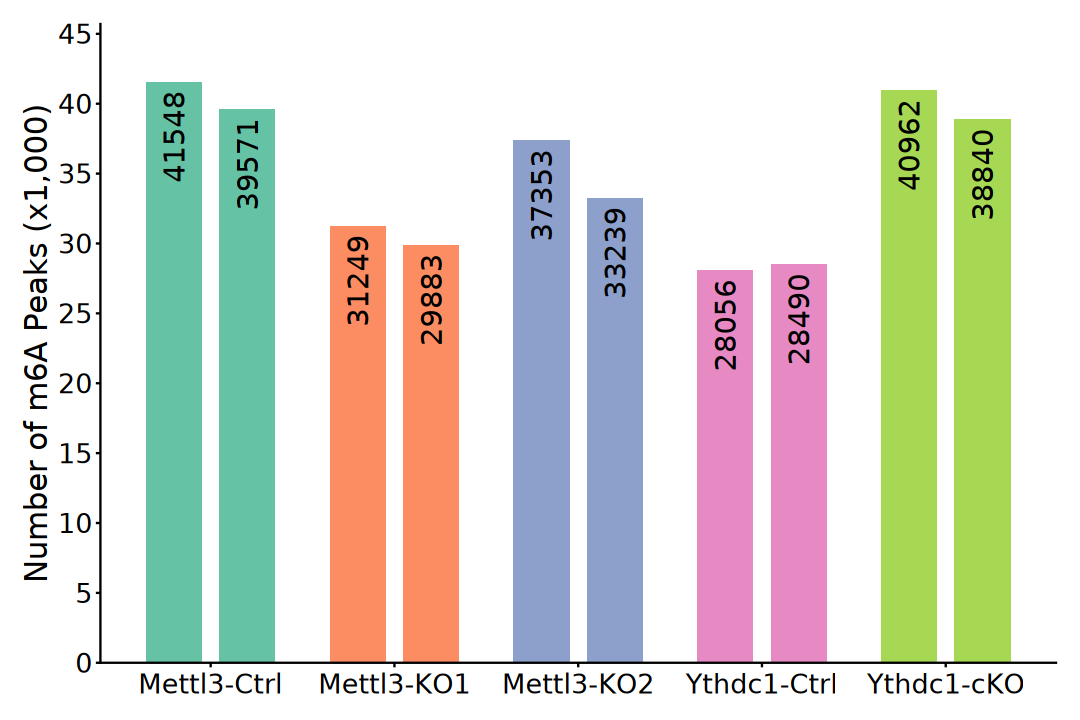

In [10]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(Genotype, number, group = Replicate)) +
    geom_bar(
        aes(fill = Genotype), stat = "identity", width = 0.6, 
        position = position_dodge(width = 0.8)) +
    geom_text(
        aes(label = number), angle = 90, hjust = 1.1, vjust = 0.5, size = 6, 
        position = position_dodge(width = 0.8)) +
    scale_y_continuous(
        breaks = seq(0, 50000, 5000), labels = seq(0, 50, 5), 
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Number of m6A Peaks (x1,000)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "none", 
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 0, vjust = 0.5), 
        axis.text.y = element_text(size = 16))

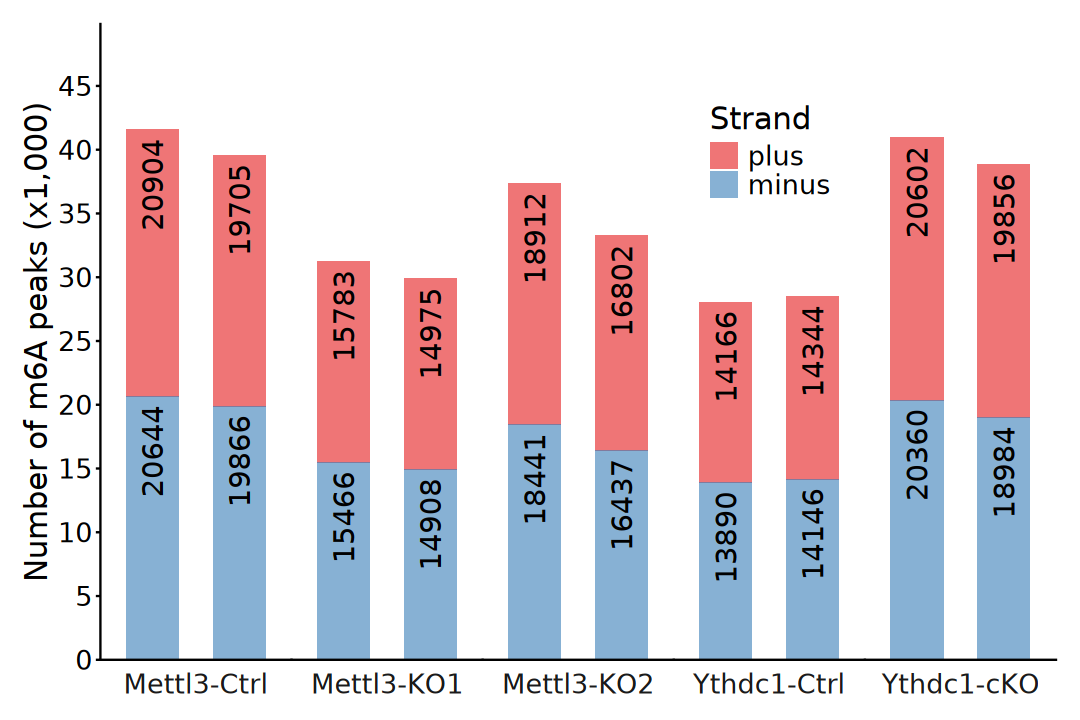

In [11]:
options(repr.plot.width = 9, repr.plot.height = 6)

plot_df |>
    pivot_longer(
        cols = c(number_plus, number_minus), names_to = "Strand", 
        names_prefix = "number_", values_to = "Count"
    ) |>
    mutate(Strand = factor(Strand, levels = c("plus", "minus"))) |>
ggplot(aes(x = Replicate, y = Count, fill = Strand)) +
    geom_bar(
        stat = "identity", alpha = 0.6, width = 0.6, 
        position = position_stack()) +
    geom_text(
        aes(label = Count), angle = 90, hjust = 1.1, vjust = 0.5, size = 6, 
        position = position_stack()) +
    facet_wrap(~ Genotype, nrow = 1, strip.position = "bottom") +
    scale_y_continuous(
        breaks = seq(0, 50000, 5000), labels = seq(0, 50, 5), 
        expand = expansion(mult = c(0, 0.2))) +
    scale_fill_brewer(palette = "Set1") +
    labs(x = NULL, y = "Number of m6A peaks (x1,000)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing.x = unit(0, "lines"), 
        strip.placement = "outside", 
        strip.background = element_blank(), 
        strip.text.x = element_text(size = 16, margin = margin(t = 4)),
        legend.position = "inside",
        legend.position.inside = c(0.7, 0.8), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_blank(), 
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank())

## 3). Replicate Consistency

In [12]:
# ------------------------------------------------------------------------------
# Function: summarize_peak_overlaps
#
# Description:
# Summarize the overlap composition of peak sets across replicates.
#
# Arguments:
#   peaks_list : named list of GRanges.
#   peaks      : short names used for display and ordering.
#                Default: rep1, rep2, ..., repN.
# ------------------------------------------------------------------------------
summarize_peak_overlaps <- function(
    peaks_list, peaks = paste0("rep", seq_along(peaks_list)), 
    ignore.strand = TRUE) {

    names(peaks_list) <- peaks

    comb_levels <- unlist(
        lapply(seq_along(peaks), function(i) {
            combn(peaks, i, FUN = paste, collapse = "&")
        }), use.names = FALSE)

    ol <- lapply(peaks_list, function(gr) {
            names(gr) <- gr$name
            return(gr)
        }) |>
            ChIPpeakAnno::findOverlapsOfPeaks(
                ignore.strand = ignore.strand)

    ol$venn_cnt[, c(names(peaks_list), "Counts"), drop = FALSE] |>
        as.data.frame(stringsAsFactors = FALSE) |>
        dplyr::rename_with(~ peaks, .cols = names(peaks_list)) |>
        dplyr::rowwise() |>
        dplyr::mutate(
            Combination = {
                present <- peaks[c_across(dplyr::all_of(peaks)) == 1]
                if (length(present) == 0) {
                    NA_character_
                } else {
                    paste(present, collapse = "&")
                }
            }
        ) |>
        dplyr::ungroup() |>
        dplyr::mutate(
            Combination = factor(Combination, levels = comb_levels)) |>
        dplyr::filter(!is.na(Combination)) |>
        dplyr::select(Combination, Counts) |>
        as.data.frame()
}

In [13]:
overlap_summary <- coldata |>
    split(~ Genotype) |>
    purrr::map(~ summarize_peak_overlaps(
        filtered_peaks_list[rownames(.x)], ignore.strand = FALSE)) |>
    dplyr::bind_rows(.id = "Genotype")

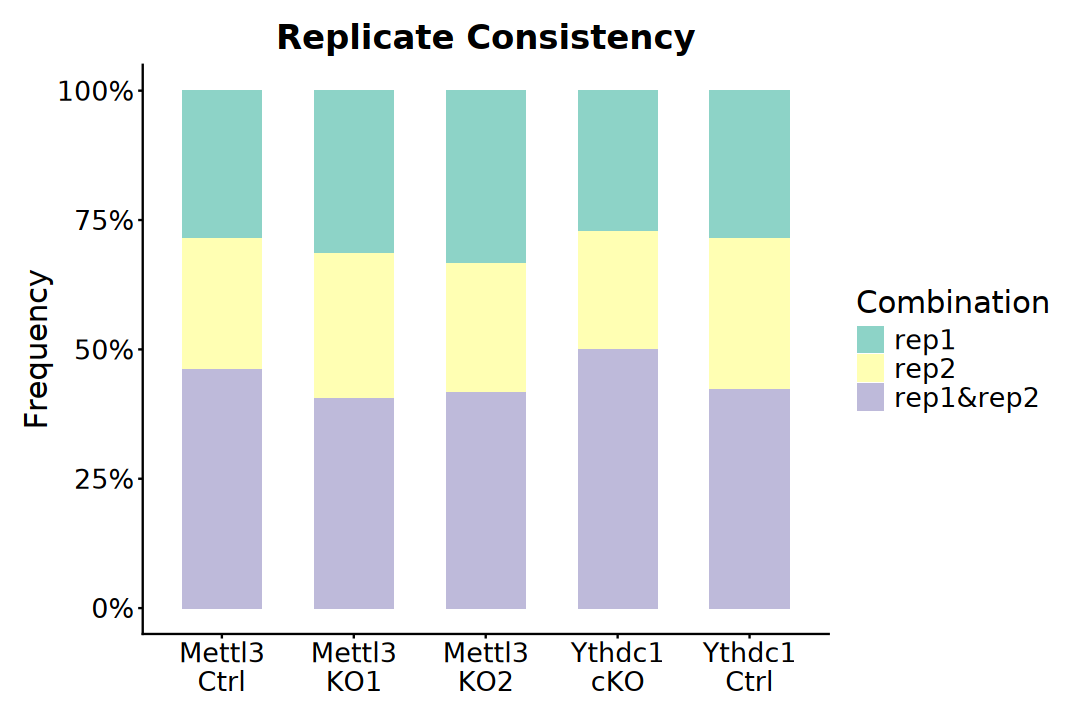

In [14]:
options(repr.plot.width = 9, repr.plot.height = 6)

overlap_summary |>
    mutate(Group = str_replace_all(Genotype, "-", "\n")) |>
ggplot(aes(x = Group, y = Counts, fill = Combination)) +
    geom_bar(stat = "identity", position = "fill", width = 0.6) +
    scale_y_continuous(labels = scales::percent_format()) +
    scale_fill_brewer(palette = "Set3") +
    labs(title = "Replicate Consistency", x = NULL, y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). Peak Annotation

In [15]:
suppressPackageStartupMessages(library(ChIPseeker))

In [16]:
# Annotate m6A peaks at transcript level
peaks_anno_list <- lapply(
    peaks_list, 
    annotatePeak, 
    TxDb = txdb, 
    tssRegion = c(0, 0), 
    level = "transcript", 
    sameStrand = TRUE, 
    genomicAnnotationPriority = c(
        "5UTR", "3UTR", "Exon", "Intron", 
        "Promoter", "Downstream", "Intergenic"), 
    verbose = FALSE
)

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


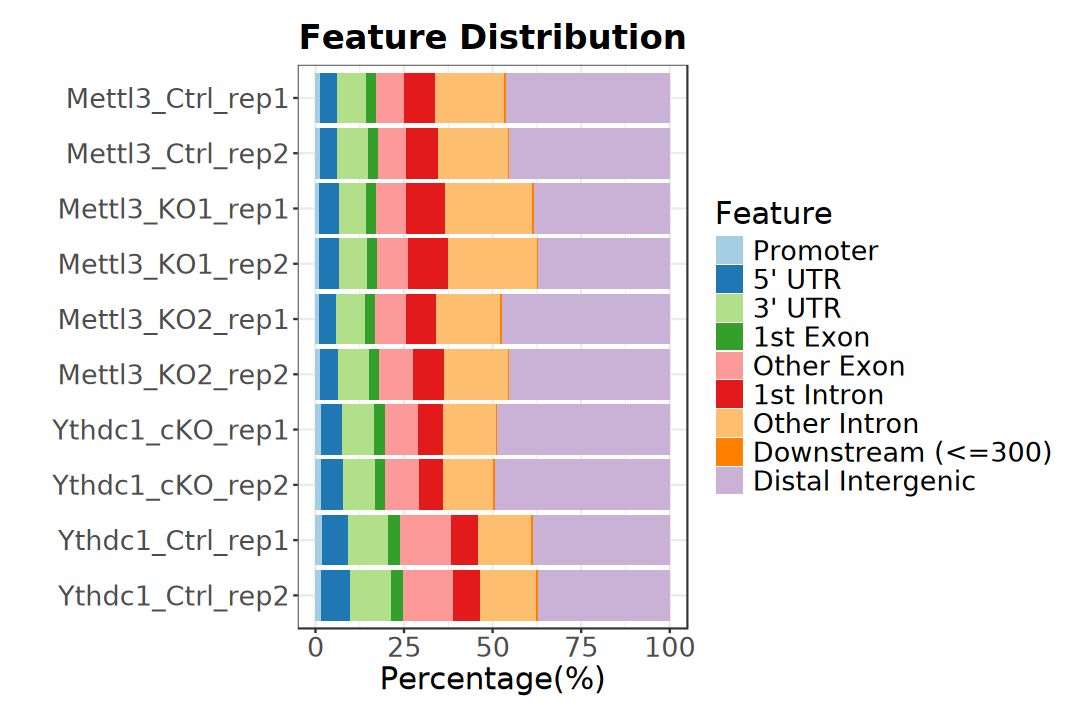

In [18]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotAnnoBar(peaks_anno_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [ ]:
# Simplify transcript-region annotation
format_peak_annotation <- function(anno) {
    anno@anno |>
        as.data.frame() |>
        mutate(
            Category = case_when(
                grepl("5' UTR", annotation, fixed = TRUE) ~ "5' UTR",
                grepl("3' UTR", annotation, fixed = TRUE) ~ "3' UTR",
                grepl("Exon", annotation, fixed = TRUE) ~ "CDS",
                grepl("Intron", annotation, fixed = TRUE) ~ "Intron",
                TRUE ~ "Intergenic"
            )
        ) |>
        as("GRanges")
}

In [ ]:
peaks_anno_list <- lapply(peaks_anno_list, format_peak_annotation)

In [20]:
# Prepare transcript biotype information
tx_info <- data.frame(
    transcript_id = as.character(gtf$transcript_id),
    gene_type = as.character(gtf$gene_type)
) |>
    filter(
        !is.na(transcript_id), transcript_id != "", 
        !is.na(gene_type), gene_type != "") |>
    distinct(transcript_id, .keep_all = TRUE)

In [21]:
# Collapse detailed GENCODE gene types into broader categories
collapse_gene_type <- function(x) {
    x <- as.character(x)
    case_when(
        is.na(x) | x == "" ~ NA_character_,
        grepl("pseudogene", x) ~ "pseudogene",
        x == "protein_coding" | 
            grepl("^(IG|TR)_.+_gene$", x) ~ "protein_coding",
        x == "lncRNA" ~ "lncRNA",
        x %in% c(
            "miRNA", "snRNA", "snoRNA", "scaRNA", "sRNA", "scRNA",
            "vault_RNA", "vaultRNA", "tRNA", "Mt_tRNA") ~ "small_RNA",
        x %in% c("rRNA", "Mt_rRNA") ~ "rRNA",
        TRUE ~ "other"
    )
}

In [22]:
# Add gene type to annotated peaks
add_gene_type <- function(gr) {
    idx <- match(gr$transcriptId, tx_info$transcript_id)
    gr$gene_type <- collapse_gene_type(tx_info$gene_type[idx])
    gr
}

In [23]:
peaks_anno_list <- lapply(peaks_anno_list, add_gene_type)

In [24]:
plot_df <- map_dfr(peaks_anno_list, ~ as.data.frame(.x), .id = "sample") |>
    mutate(gene_type = replace_na(gene_type, "unannotated")) |>
    count(sample, gene_type, name = "n") |>
    group_by(sample) |>
    mutate(percent = n / sum(n) * 100) |>
    ungroup() |>
    mutate(gene_type = factor(gene_type, levels = c(
        "protein_coding", "lncRNA", "small_RNA", "rRNA",
        "pseudogene", "other", "unannotated"))) |>
    mutate(sample = sub("HCCLM3_ALKBH5_", "", sample))

head(plot_df)

sample,gene_type,n,percent
<chr>,<fct>,<int>,<dbl>
Mettl3_Ctrl_rep1,lncRNA,23056,13.6110324
Mettl3_Ctrl_rep1,other,8346,4.9270332
Mettl3_Ctrl_rep1,protein_coding,99867,58.9561491
Mettl3_Ctrl_rep1,pseudogene,27651,16.3236753
Mettl3_Ctrl_rep1,rRNA,636,0.3754605
Mettl3_Ctrl_rep1,small_RNA,9836,5.8066497


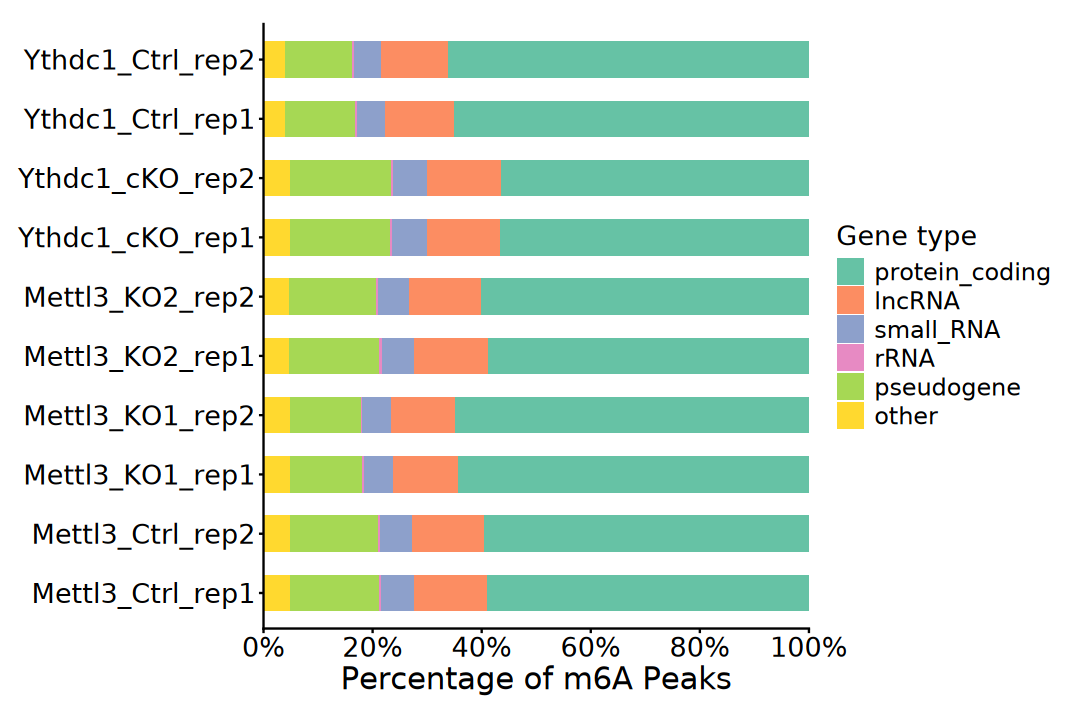

In [25]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(sample, percent, fill = gene_type)) +
    geom_bar(stat = "identity", width = 0.6) +
    scale_y_continuous(
        breaks = seq(0, 100, 20), labels = paste0(seq(0, 100, 20), "%"),
        expand = expansion(mult = c(0, 0))) +
    scale_fill_brewer(palette = "Set2") +
    coord_flip() +
    labs(x = NULL, y = "Percentage of m6A Peaks", fill = "Gene type") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 16),
        legend.text = element_text(size = 14),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 5). Guitar Plot

In [26]:
suppressPackageStartupMessages(library(Guitar))

In [27]:
guitarTxdb <- makeGuitarTxdb(
    txdb, txpromoterLength = 0, txtailLength = 0,
    pltTxType =  "mrna", withTxContext = TRUE)

[1] "There are 142314 transcripts of 55298 genes in the genome."
[1] "total 142314 transcripts extracted ..."
[1] "total 98263 transcripts left after ambiguity filter ..."
[1] "total 98263 transcripts left after check chromosome validity ..."
[1] "total 16306 mRNAs left after component length filter ..."
[1] "total 47891 ncRNAs left after ncRNA length filter ..."
[1] "generate components for mRNA"
[1] "generate chiped transcriptome"
[1] "generate coverage checking ranges for mrna"


In [28]:
str(guitarTxdb$mrna$componentWidthAverage_pct)

 Named num [1:5] 0 0.126 0.46 0.414 0
 - attr(*, "names")= chr [1:5] "promoter" "utr5" "cds" "utr3" ...


In [29]:
txMrnaComponentProp <- guitarTxdb$mrna$componentWidthAverage_pct

In [30]:
# ~5 min
plot_guitar_dat <- GuitarPlot(
    txTxdb = txdb, 
    stGRangeLists = filtered_peaks_list, 
    headOrtail = FALSE, 
    enableCI = FALSE, 
    mapFilterTranscript = TRUE, 
    pltTxType = "mrna", 
    stGroupName = names(filtered_peaks_list))

[1] "20260920174718"
[1] "There are 142314 transcripts of 55298 genes in the genome."
[1] "total 142314 transcripts extracted ..."
[1] "total 98263 transcripts left after ambiguity filter ..."
[1] "total 98263 transcripts left after check chromosome validity ..."
[1] "total 16306 mRNAs left after component length filter ..."
[1] "total 47891 ncRNAs left after ncRNA length filter ..."
[1] "generate components for mRNA"
[1] "generate chiped transcriptome"
[1] "generate coverage checking ranges for mrna"
[1] "20260920175002"
[1] "sample 10 points for Mettl3_Ctrl_rep1"


Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
"GRanges object contains 52 out-of-bound ranges located on sequences
  ENSMUST00000015645.10, ENSMUST00000001806.9, ENSMUST00000036376.12,
  ENSMUST00000107037.7, ENSMUST00000052691.8, ENSMUST00000061859.6,
  ENSMUST00000059787.14, ENSMUST00000236685.1, ENSMUST00000183662.7,
  ENSMUST00000106252.8, ENSMUST00000097886.3, ENSMUST00000179556.1,
  ENSMUST00000055604.5, ENSMUST00000098644.8, ENSMUST00000171155.3,
  ENSMUST00000032910.12, ENSMUST00000034048.12, ENSMUST00000179926.8,
  ENSMUST00000034205.4, ENSMUST00000212075.1, ENSMUST00000170489.1,
  ENSMUST00000058688.6, ENSMUST00000111859.7, ENSMUST00000003436.11,
  ENSMUST00000007921.8, ENSMUST00000144910.1, ENSMUST00000046266.12,
  ENSMUST00000026367.10, ENSMUST00000049530.13, ENSMUST00000025025.6,
  ENSMUST00000235795.1, ENSMUST00000110661.8, ENSMUST00000028633.12,
  ENSMUST00000207917.1, ENSMUST00000168755.6, ENSMUST00000057431.5,
  ENSMUST00000041606.13, ENSMUST0

[1] "sample 10 points for Mettl3_Ctrl_rep2"


Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
"GRanges object contains 37 out-of-bound ranges located on sequences
  ENSMUST00000074525.9, ENSMUST00000116376.8, ENSMUST00000107037.7,
  ENSMUST00000236685.1, ENSMUST00000118470.7, ENSMUST00000043983.10,
  ENSMUST00000183662.7, ENSMUST00000199100.4, ENSMUST00000055604.5,
  ENSMUST00000080885.11, ENSMUST00000034048.12, ENSMUST00000034205.4,
  ENSMUST00000212075.1, ENSMUST00000170489.1, ENSMUST00000081834.9,
  ENSMUST00000007921.8, ENSMUST00000039949.4, ENSMUST00000001548.13,
  ENSMUST00000144910.1, ENSMUST00000170153.1, ENSMUST00000025025.6,
  ENSMUST00000168755.6, ENSMUST00000055028.8, ENSMUST00000163946.1,
  ENSMUST00000106091.8, ENSMUST00000108546.1, ENSMUST00000210282.1,
  ENSMUST00000107431.2, ENSMUST00000060783.6, ENSMUST00000056157.13,
  ENSMUST00000190157.6, ENSMUST00000115351.9, ENSMUST00000041459.8,
  ENSMUST00000054414.4, and ENSMUST00000114147.1. Note that ranges located on a
  sequence whose length is

[1] "sample 10 points for Mettl3_KO1_rep1"


Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
"GRanges object contains 36 out-of-bound ranges located on sequences
  ENSMUST00000015645.10, ENSMUST00000039259.6, ENSMUST00000122902.7,
  ENSMUST00000219197.1, ENSMUST00000042360.4, ENSMUST00000052691.8,
  ENSMUST00000059787.14, ENSMUST00000113278.8, ENSMUST00000097886.3,
  ENSMUST00000199100.4, ENSMUST00000047760.9, ENSMUST00000055604.5,
  ENSMUST00000098644.8, ENSMUST00000032910.12, ENSMUST00000034048.12,
  ENSMUST00000212075.1, ENSMUST00000170489.1, ENSMUST00000120638.7,
  ENSMUST00000144910.1, ENSMUST00000046266.12, ENSMUST00000096347.3,
  ENSMUST00000049530.13, ENSMUST00000023351.10, ENSMUST00000025025.6,
  ENSMUST00000050776.8, ENSMUST00000111996.7, ENSMUST00000165219.7,
  ENSMUST00000168755.6, ENSMUST00000196397.4, ENSMUST00000066041.11,
  ENSMUST00000108546.1, ENSMUST00000107431.2, ENSMUST00000060783.6,
  ENSMUST00000034452.11, ENSMUST00000054414.4, and ENSMUST00000114147.1. Note
  that ranges located on 

... (12 outputs left out)

[1] "sample 10 points for Ythdc1_Ctrl_rep2"


Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
"GRanges object contains 62 out-of-bound ranges located on sequences
  ENSMUST00000186368.6, ENSMUST00000107636.3, ENSMUST00000109958.2,
  ENSMUST00000127442.7, ENSMUST00000109456.8, ENSMUST00000183662.7,
  ENSMUST00000050850.13, ENSMUST00000097886.3, ENSMUST00000118993.7,
  ENSMUST00000032174.11, ENSMUST00000047760.9, ENSMUST00000120836.7,
  ENSMUST00000053109.4, ENSMUST00000055604.5, ENSMUST00000098644.8,
  ENSMUST00000080885.11, ENSMUST00000171155.3, ENSMUST00000098088.10,
  ENSMUST00000034048.12, ENSMUST00000034205.4, ENSMUST00000061209.6,
  ENSMUST00000058688.6, ENSMUST00000111859.7, ENSMUST00000003436.11,
  ENSMUST00000007921.8, ENSMUST00000021119.8, ENSMUST00000045923.9,
  ENSMUST00000144910.1, ENSMUST00000046266.12, ENSMUST00000064517.8,
  ENSMUST00000170153.1, ENSMUST00000096347.3, ENSMUST00000049530.13,
  ENSMUST00000232540.1, ENSMUST00000025025.6, ENSMUST00000002839.8,
  ENSMUST00000028633.12, ENSMUST000

[1] "start figure plotting for mrna ..."


Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the Guitar package.
  Please report the issue to the authors."


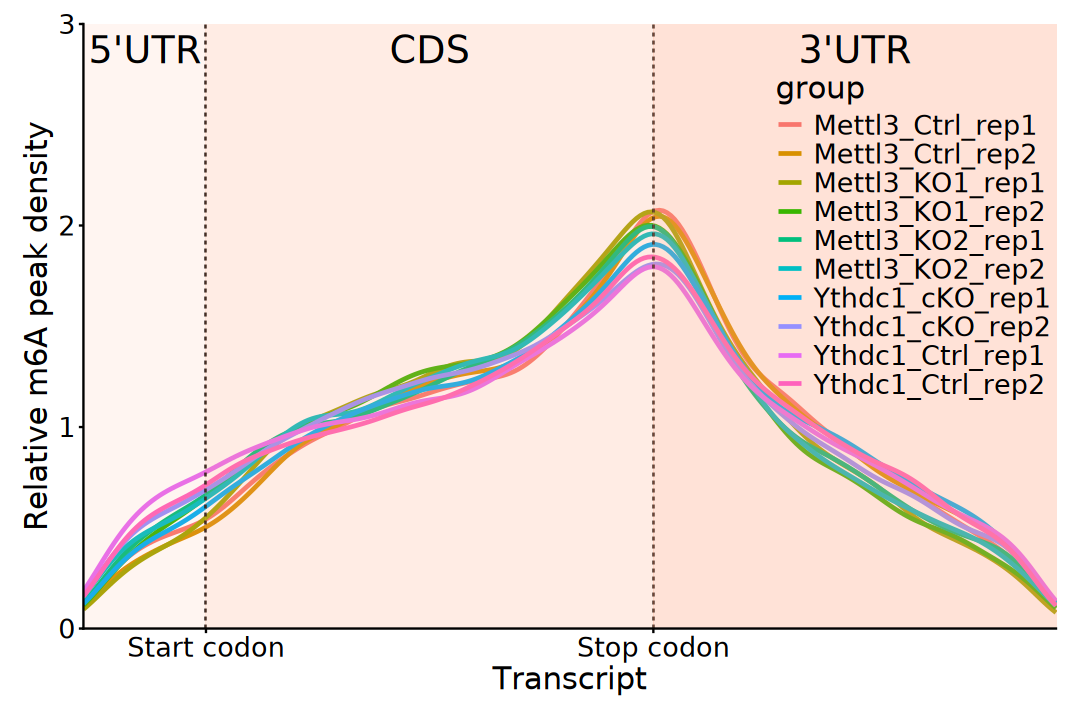

In [31]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_guitar_dat$data, aes(x = x, y = density, colour = group)) +
    geom_line(alpha = 1, linewidth = 1) +
    geom_vline(
        aes(xintercept = sum(txMrnaComponentProp[1:2])), linetype = "dashed") + 
    geom_vline(
        aes(xintercept = sum(txMrnaComponentProp[1:3])), linetype = "dashed") + 
    annotate(
        "rect", xmin = 0, xmax = sum(txMrnaComponentProp[1:2]), 
        ymin = 0, ymax = 3, fill = "LightSalmon", alpha = 0.1) +
    annotate(
        "rect", xmin = sum(txMrnaComponentProp[1:2]), 
        xmax = sum(txMrnaComponentProp[1:3]), 
        ymin = 0, ymax = 3, fill = "LightSalmon", alpha = 0.2) +
    annotate(
        "rect", xmin = sum(txMrnaComponentProp[1:3]), xmax = 1, 
        ymin = 0, ymax = 3, fill = "LightSalmon", alpha = 0.3) +
    annotate("text", x = 0.063, y = 3, label = "5'UTR", vjust = 1.4, size = 8) +
    annotate("text", x = 0.356, y = 3, label = "CDS", vjust = 1.4, size = 8) +
    annotate("text", x = 0.793, y = 3, label = "3'UTR", vjust = 1.4, size = 8) +
    scale_x_continuous(
        breaks = c(
            sum(txMrnaComponentProp[1:2]), 
            sum(txMrnaComponentProp[1:3])), 
        labels = c("Start codon", "Stop codon"), expand = c(0, 0)) +
    scale_y_continuous(expand = c(0, 0)) +
    labs(x = "Transcript", y = "Relative m6A peak density") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing.x = unit(0, "lines"), 
        strip.placement = "outside", 
        strip.background = element_blank(), 
        strip.text.x = element_text(size = 16, margin = margin(t = 4)),
        legend.position = "inside",
        legend.position.inside = c(0.85, 0.65),
        legend.background = element_blank(),
        legend.key = element_rect(fill = NA),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 6). Peak Metagene

In [ ]:
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [ ]:
# The longest transcript of each gene was selected from Gencode GTF file. 
# Transcripts with 5′UTRs length <50 bp or 3′UTRs length <100 bp or 
# CDS length <100 bp were filtered.
protein_coding_transcript <- transcriptLengths(
    txdb, with.cds_len = TRUE, with.utr5_len = TRUE, with.utr3_len = TRUE) |>
    as.data.frame() |> 
    group_by(gene_id) |>
    filter(tx_len == max(tx_len)) |> 
    filter(utr5_len >= 50, utr3_len >= 100, cds_len >= 100)

In [ ]:
fiveutrs <- fiveUTRsByTranscript(txdb, use.names = TRUE)
fiveutrs <- fiveutrs[proteinCodingTranscript$tx_name]
fiveutrs_long <- GRangesList(lapply(fiveutrs, function(gr) {
    gr[which.max(width(gr))]
})) |> unlist()

In [ ]:
cdss <- cdsBy(txdb, by = "tx", use.names = TRUE)
cdss <- cdss[proteinCodingTranscript$tx_name]
cdss_long <- GRangesList(lapply(cdss, function(gr) {
    gr[which.max(width(gr))]
})) |> unlist()

In [ ]:
threeutrs <- threeUTRsByTranscript(txdb, use.names = TRUE)
threeutrs <- threeutrs[proteinCodingTranscript$tx_name]
threeutrs_long <- GRangesList(lapply(threeutrs, function(gr) {
    gr[which.max(width(gr))]
})) |> unlist()

In [ ]:
mat_5utr <- normalizeToMatrix(
    peaksList[[1]], fiveutrs_long, target_ratio = 1, extend = 0, k = 10)
colnames(mat_5utr) <- paste0("u", seq(1,10))
mat_cds <- normalizeToMatrix(
    peaksList[[1]], cdss_long, target_ratio = 1, extend = 0, k = 20)
mat_3utr <- normalizeToMatrix(
    peaksList[[1]], threeutrs_long, target_ratio = 1, extend = 0, k = 20)
colnames(mat_3utr) <- paste0("d", seq(1,20))

In [ ]:
mat <- merge(mat_5utr, mat_cds, by = "row.names")
mat <- merge(mat, mat_3utr, by.x = "Row.names", by.y = "row.names")
mat <- column_to_rownames(mat, "Row.names")
mat <- as.matrix(mat)
head(mat)

In [ ]:
normMat <- as.normalizedMatrix(
    mat, k_upstream = 10, k_target = 20, k_downstream = 20, 
    extend = c(1000, 2000), signal_name = "m6A", target_name = "CDS")

In [ ]:
color_palette <- colorRampPalette(brewer.pal(9, "Blues"))(100)

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 9)
EnrichedHeatmap(
    normMat, col = color_palette, name = "m6A", row_km = 5,
    top_annotation = HeatmapAnnotation(
        enriched = anno_enriched(gp = gpar(col = 1:5))), 
    use_raster = FALSE)